/Users/onkarpadole/Documents/practical/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Weather Data:
                  Date  Temperature  Humidity  WindSpeed  Precipitation
0 2026-11-15 15:00:00        22.77        34       1.62              0
1 2026-11-15 18:00:00        21.55        38       1.06              0
2 2026-11-15 21:00:00        18.47        44       0.96              0
3 2026-11-16 00:00:00        17.80        47       0.93              0
4 2026-11-16 03:00:00        22.34        40       1.21              0

Weather Statistics:
        Temperature   Humidity  WindSpeed  Precipitation
count    40.000000  40.000000   40.00000           40.0
mean     23.768500  39.450000    1.89975            0.0
std       3.959611   9.394352    1.18092            0.0
min      17.530000  20.000000    0.35000            0.0
25%      20.677500  32.500000    1.11750            0.0
50%      22.760000  40.000000    1.51000            0.0
75%      27.457500  47.000000    2.26250            0.0
max      31.940000  57.000000    4.80000            0.0

Average Temperature: 23.77 °C
Ma

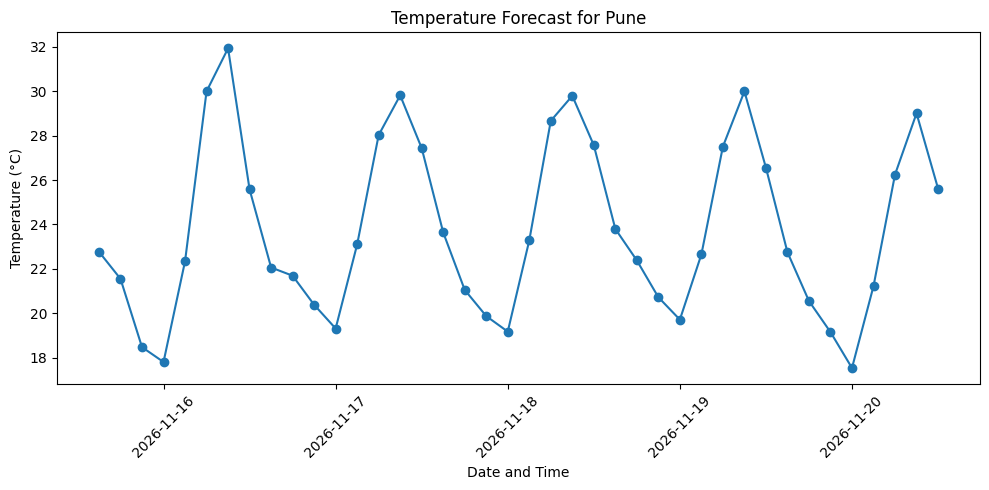

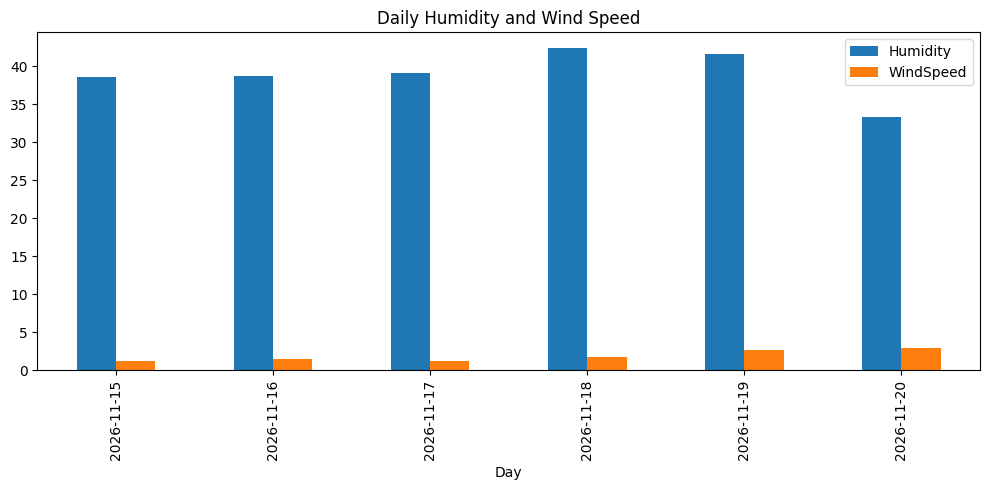

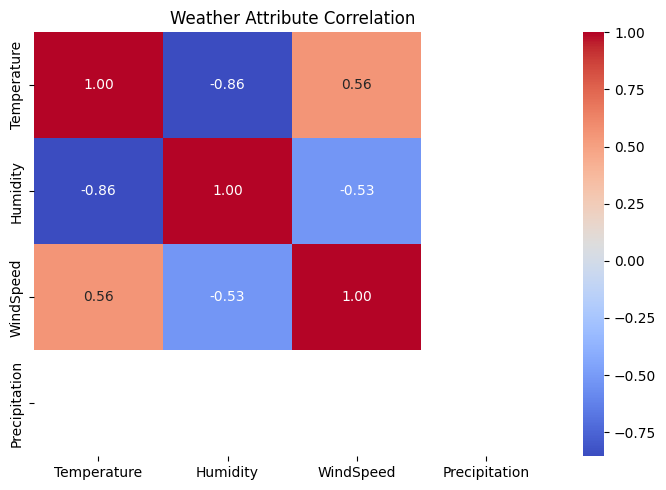


Weather data saved successfully.


In [1]:
#8.weather_api_analysis
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# API configuration
API_KEY = "6ceb4c82011d8491691bedf8143d3b65"
CITY = "Pune"

url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    "q": CITY,
    "appid": API_KEY,
    "units": "metric"
}

# Retrieve weather data
response = requests.get(url, params=params, timeout=20)

if response.status_code != 200:
    print("API Error:", response.status_code, response.text)
else:
    data = response.json()

    # Extract weather attributes
    records = []

    for item in data["list"]:
        records.append({
            "Date": item["dt_txt"],
            "Temperature": item["main"].get("temp"),
            "Humidity": item["main"].get("humidity"),
            "WindSpeed": item["wind"].get("speed"),
            "Precipitation": item.get("rain", {}).get("3h", 0)
        })

    df = pd.DataFrame(records)

    # Clean and preprocess data
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    cols = ["Temperature", "Humidity", "WindSpeed", "Precipitation"]
    df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=["Date", "Temperature", "Humidity",
                           "WindSpeed"])

    print("Weather Data:\n", df.head())

    # Statistical analysis
    print("\nWeather Statistics:\n", df[cols].describe())
    print("\nAverage Temperature:",
          round(df["Temperature"].mean(), 2), "°C")
    print("Maximum Temperature:",
          df["Temperature"].max(), "°C")
    print("Minimum Temperature:",
          df["Temperature"].min(), "°C")

    # Daily aggregation
    df["Day"] = df["Date"].dt.date
    daily = df.groupby("Day")[cols].mean()

    print("\nDaily Weather Summary:\n", daily)

    # Temperature line plot
    plt.figure(figsize=(10, 5))
    plt.plot(df["Date"], df["Temperature"], marker="o")
    plt.title("Temperature Forecast for " + CITY)
    plt.xlabel("Date and Time")
    plt.ylabel("Temperature (°C)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Humidity and wind speed
    daily[["Humidity", "WindSpeed"]].plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Daily Humidity and Wind Speed")
    plt.tight_layout()
    plt.show()

    # Correlation heatmap
    plt.figure(figsize=(7, 5))
    sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm",
                fmt=".2f")
    plt.title("Weather Attribute Correlation")
    plt.tight_layout()
    plt.show()

    # Save results
    df.to_csv("weather_data.csv", index=False)
    print("\nWeather data saved successfully.")